# 02. Hồi quy tuyến tính trên dữ liệu giá xe

**Mục tiêu học:** hiểu mô hình tuyến tính từ baseline đến diễn giải; thấy vì sao `log(giá)` giúp ích; biết Ridge/Lasso hoạt động ra sao khi có nhiều biến one-hot và biến tương quan.

**Liên hệ lý thuyết:** notebook `LinearRegression.ipynb` (thư mục MACHINE_LEARNING) có phần toán và giả định của OLS.

**Nội dung**
1. Chia dữ liệu và đo baseline ngớ ngẩn nhất
2. Hồi quy tuyến tính trên giá thô
3. Hồi quy tuyến tính trên log(giá)
4. Phân tích phần dư
5. Diễn giải hệ số: "mỗi năm xe mất bao nhiêu %?"
6. Đa cộng tuyến
7. Ridge và Lasso
8. Tổng kết

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

from used_car_price.config import FEATURES, CATEGORICAL, NUMERIC, TARGET, RANDOM_STATE, RAW_PATH, TEST_SIZE
from used_car_price.data import load_data
from used_car_price.features import build_preprocessor
from used_car_price.train import log_target
from used_car_price.metrics import evaluate

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (7, 4.2)

from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

## 1. Chia dữ liệu và baseline ngớ ngẩn nhất

In [2]:
df = load_data()
X, y = df[FEATURES], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print(f"Train: {len(X_tr)} | Test: {len(X_te)}  (tập test chỉ dùng để đánh giá cuối)")

# Baseline 0: luôn dự đoán giá trung bình/trung vị của tập train
rows = {"luôn đoán trung bình": evaluate(y_te, np.full(len(y_te), y_tr.mean())),
        "luôn đoán trung vị": evaluate(y_te, np.full(len(y_te), y_tr.median()))}
display(pd.DataFrame(rows).T.round(3))

Train: 2279 | Test: 570  (tập test chỉ dùng để đánh giá cuối)


,MAPE,sai_so_%_trung_vi,MAE,RMSE,R2
luôn đoán trung bình,1.211,0.813,838.027,1243.336,-0.000
luôn đoán trung vị,0.652,0.527,696.577,1304.988,-0.102


Mọi mô hình phải thắng được baseline này. Chú ý **R² ≈ 0** của baseline trung bình: R² đo mô hình tốt hơn "luôn đoán trung bình" bao nhiêu.

## 2. Hồi quy tuyến tính trên giá thô

In [3]:
lin_raw = Pipeline([("prep", build_preprocessor()), ("model", LinearRegression())]).fit(X_tr, y_tr)
pred_raw = lin_raw.predict(X_te)
print("Tuyến tính trên giá thô:", {k: round(v, 3) for k, v in evaluate(y_te, pred_raw).items()})
print("Số dự đoán ÂM:", int((pred_raw < 0).sum()), "trên", len(pred_raw), "xe  <- giá không thể âm!")

Tuyến tính trên giá thô: {'MAPE': 0.395, 'sai_so_%_trung_vi': 0.2, 'MAE': 304.403, 'RMSE': 556.42, 'R2': 0.8}
Số dự đoán ÂM: 27 trên 570 xe  <- giá không thể âm!


## 3. Hồi quy tuyến tính trên log(giá)

Dùng `TransformedTargetRegressor`: huấn luyện trên `log1p(giá)`, tự đổi ngược khi dự đoán. Dự đoán luôn dương.

In [4]:
lin_log = log_target(Pipeline([("prep", build_preprocessor()), ("model", LinearRegression())])).fit(X_tr, y_tr)
pred_log = lin_log.predict(X_te)
cmp = pd.DataFrame({"giá thô": evaluate(y_te, pred_raw), "log(giá)": evaluate(y_te, pred_log)}).T
display(cmp.round(3))
print("Số dự đoán âm với log(giá):", int((pred_log < 0).sum()))

,MAPE,sai_so_%_trung_vi,MAE,RMSE,R2
giá thô,0.395,0.200,304.403,556.420,0.800
log(giá),0.158,0.094,190.264,440.092,0.875


Số dự đoán âm với log(giá): 0


**Quan sát:** `R²` và `RMSE` có thể không cải thiện nhiều (hoặc thậm chí kém hơn) vì chúng bị chi phối bởi xe sang; nhưng **sai số phần trăm** cải thiện rõ. Chọn độ đo phù hợp với mục tiêu là một nửa công việc.

## 4. Phân tích phần dư

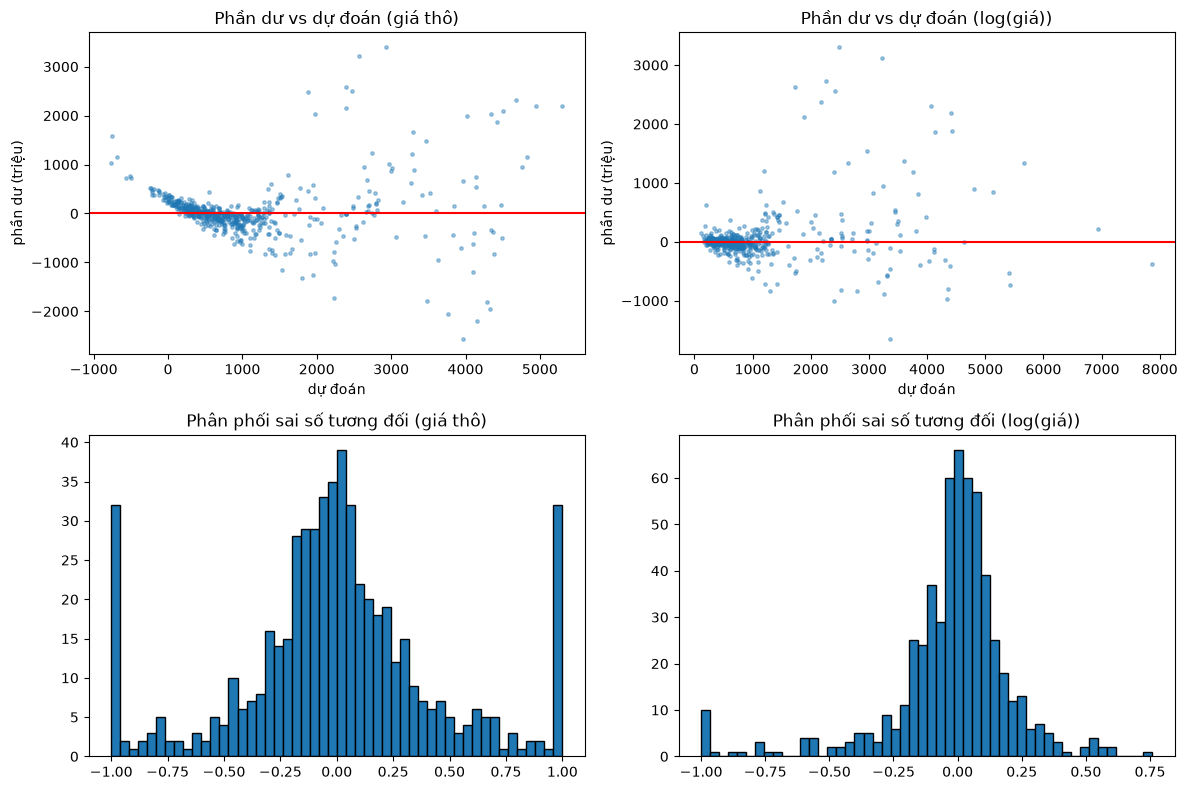

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for col, (pred, nm) in enumerate([(pred_raw, "giá thô"), (pred_log, "log(giá)")]):
    ax[0, col].scatter(pred, y_te - pred, s=6, alpha=.4); ax[0, col].axhline(0, c="r")
    ax[0, col].set_title(f"Phần dư vs dự đoán ({nm})"); ax[0, col].set_xlabel("dự đoán"); ax[0, col].set_ylabel("phần dư (triệu)")
    rel = (y_te - pred) / y_te
    ax[1, col].hist(rel.clip(-1, 1), bins=50, edgecolor="k"); ax[1, col].set_title(f"Phân phối sai số tương đối ({nm})")
plt.tight_layout(); plt.show()

**Dấu hiệu cần để ý:**
- Phần dư của mô hình trên giá thô có dạng **hình phễu** (xe đắt sai nhiều hơn): vi phạm giả định phương sai không đổi (heteroscedasticity).
- Sau khi lấy log, sai số tương đối cân bằng hơn.

## 5. Diễn giải hệ số: "mỗi năm xe mất bao nhiêu %?"

Với mô hình `log(giá) = b0 + b1·age + ...`, tăng `age` thêm 1 thì giá nhân với `exp(b1)`, tức thay đổi `(exp(b1) − 1)·100%`. Để hệ số có ý nghĩa trực tiếp ta dùng biến chưa chuẩn hoá (km tính theo 10.000 km).

In [6]:
d = df.copy(); d["km_10k"] = d["km"] / 10_000
top_brands = d["brand"].value_counts().head(10).index
d["brand_g"] = np.where(d["brand"].isin(top_brands), d["brand"], "Khác")
Xd = pd.get_dummies(d[["brand_g", "gearbox", "fuel", "origin"]], drop_first=True).join(d[["age", "km_10k", "seats"]]).astype(float)
ols = LinearRegression().fit(Xd, np.log(d[TARGET]))
coef = pd.Series(ols.coef_, index=Xd.columns)
effect = ((np.exp(coef) - 1) * 100).round(1).rename("thay đổi giá (%)")

print("Hãng làm mốc so sánh (bị bỏ do drop_first):", sorted(top_brands.tolist() + ["Khác"])[0])
print(f"Mỗi năm tuổi xe: giá thay đổi {effect['age']}%  |  mỗi 10.000 km: {effect['km_10k']}%  |  mỗi chỗ ngồi thêm: {effect['seats']}%")
display(effect.sort_values().to_frame())

Hãng làm mốc so sánh (bị bỏ do drop_first): BMW
Mỗi năm tuổi xe: giá thay đổi -6.6%  |  mỗi 10.000 km: -0.7%  |  mỗi chỗ ngồi thêm: 11.4%


,thay đổi giá (%)
brand_g_Mitsubishi,-74.2
brand_g_VinFast,-64.4
brand_g_Ford,-59.0
brand_g_Hyundai,-58.7
brand_g_Kia,-54.4
brand_g_Mazda,-54.1
brand_g_Toyota,-46.7
brand_g_Khác,-36.9
origin_trong nước,-35.5
fuel_xăng,-10.7


**Cách đọc:** hệ số của `brand_g_Toyota` là so với hãng cơ sở bị bỏ (do `drop_first`). Hệ số là **ảnh hưởng riêng khi giữ các biến khác không đổi**, khác với tương quan thô ở notebook 01.

**Thử nghĩ:** `age` và `km` tương quan mạnh, nên hệ số từng biến có thể kém ổn định. Kiểm tra bằng bootstrap bên dưới.

In [7]:
rng = np.random.default_rng(0); res = []
for _ in range(100):
    idx = rng.integers(0, len(Xd), len(Xd))
    m = LinearRegression().fit(Xd.iloc[idx], np.log(d[TARGET].iloc[idx]))
    res.append([m.coef_[Xd.columns.get_loc("age")], m.coef_[Xd.columns.get_loc("km_10k")]])
res = np.array(res)
print(f"Hệ số age   : trung bình {res[:,0].mean():.4f}, độ lệch chuẩn {res[:,0].std():.4f}")
print(f"Hệ số km_10k: trung bình {res[:,1].mean():.4f}, độ lệch chuẩn {res[:,1].std():.4f}")

Hệ số age   : trung bình -0.0666, độ lệch chuẩn 0.0045
Hệ số km_10k: trung bình -0.0083, độ lệch chuẩn 0.0029


## 6. Đa cộng tuyến: VIF cho các biến số

In [8]:
nums = d[["age", "km_10k", "seats"]]
vif = {c: 1 / (1 - LinearRegression().fit(nums.drop(columns=c), nums[c]).score(nums.drop(columns=c), nums[c])) for c in nums}
print("VIF (> 5-10 đáng lo):", {k: round(v, 2) for k, v in vif.items()})
print("Tương quan age ~ km:", round(d["age"].corr(d["km_10k"]), 2))

VIF (> 5-10 đáng lo): {'age': 1.32, 'km_10k': 1.35, 'seats': 1.03}
Tương quan age ~ km: 0.49


## 7. Ridge và Lasso

Sau one-hot ta có hàng trăm cột (mỗi dòng xe một cột), nhiều cột hiếm gặp, dễ overfit. **Ridge** co mọi hệ số, **Lasso** đưa nhiều hệ số về đúng 0.

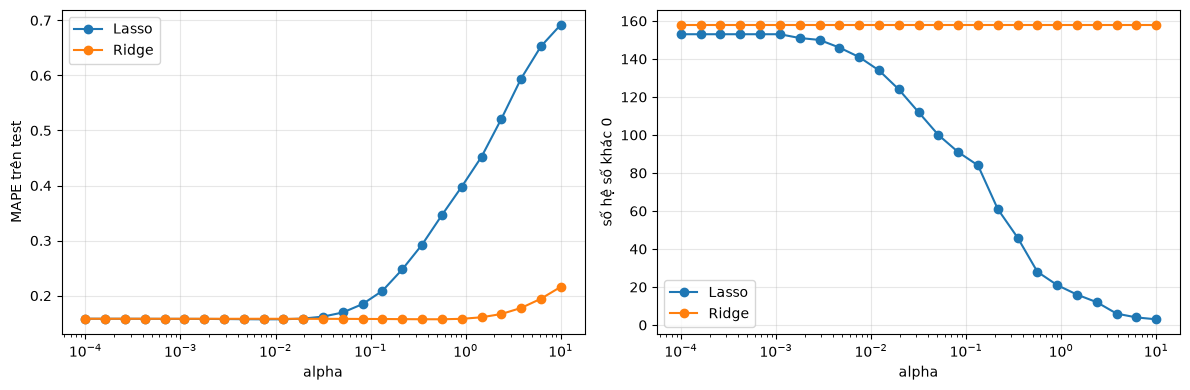

In [9]:
alphas = np.logspace(-4, 1, 25)
rows = []
for a in alphas:
    for name, M in [("Ridge", Ridge(alpha=a)), ("Lasso", Lasso(alpha=a / 100, max_iter=20000))]:
        m = log_target(Pipeline([("prep", build_preprocessor()), ("model", M)])).fit(X_tr, y_tr)
        rows.append({"mô hình": name, "alpha": a, "MAPE test": evaluate(y_te, m.predict(X_te))["MAPE"],
                     "số hệ số ≠ 0": int((m.regressor_[-1].coef_ != 0).sum())})
r = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, g in r.groupby("mô hình"): ax[0].semilogx(g["alpha"], g["MAPE test"], "o-", label=name); ax[1].semilogx(g["alpha"], g["số hệ số ≠ 0"], "o-", label=name)
ax[0].set_xlabel("alpha"); ax[0].set_ylabel("MAPE trên test"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_xlabel("alpha"); ax[1].set_ylabel("số hệ số khác 0"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [10]:
# Chọn alpha bằng cross-validation (đúng cách, không nhìn tập test)
ridge = log_target(Pipeline([("prep", build_preprocessor()), ("model", RidgeCV(alphas=np.logspace(-3, 3, 30), scoring="neg_mean_absolute_percentage_error"))])).fit(X_tr, y_tr)
lasso = log_target(Pipeline([("prep", build_preprocessor()), ("model", LassoCV(alphas=np.logspace(-5, -1, 30), cv=5, max_iter=20000))])).fit(X_tr, y_tr)
print("alpha Ridge chọn:", round(ridge.regressor_[-1].alpha_, 4), "| alpha Lasso chọn:", round(lasso.regressor_[-1].alpha_, 5))
display(pd.DataFrame({"OLS (log)": evaluate(y_te, pred_log), "Ridge": evaluate(y_te, ridge.predict(X_te)), "Lasso": evaluate(y_te, lasso.predict(X_te))}).T.round(3))

names = lasso.regressor_[0].get_feature_names_out()
lc = pd.Series(lasso.regressor_[-1].coef_, index=names)
print(f"\nLasso giữ {int((lc != 0).sum())}/{len(lc)} đặc trưng. Top 8 theo |hệ số|:")
display(lc.reindex(lc.abs().sort_values(ascending=False).index).head(8).round(3).to_frame("hệ số"))

alpha Ridge chọn: 0.3039 | alpha Lasso chọn: 9e-05


,MAPE,sai_so_%_trung_vi,MAE,RMSE,R2
OLS (log),0.158,0.094,190.264,440.092,0.875
Ridge,0.157,0.095,190.001,445.750,0.871
Lasso,0.157,0.097,190.416,445.221,0.872



Lasso giữ 140/158 đặc trưng. Top 8 theo |hệ số|:


,hệ số
cat__brand_Bentley,2.228
cat__model_Land,1.763
cat__brand_LandRover,1.569
cat__brand_Porsche,1.492
cat__model_Alphard,1.432
cat__brand_Lexus,1.303
cat__model_Sienna,1.100
cat__model_Prado,1.083


## 8. Tổng kết

- Baseline trung bình cho R² ≈ 0; mô hình tuyến tính trên **giá thô** cho dự đoán âm và phần dư hình phễu.
- **log(giá)** sửa các vấn đề trên và cho phép diễn giải theo phần trăm.
- `age` và `km` đồng biến nên hệ số riêng từng biến kém ổn định hơn; Ridge/Lasso giúp ổn định khi có nhiều cột one-hot.
- Mô hình tuyến tính khó bắt được **tương tác** (vd. xe sang mất giá theo kiểu khác xe phổ thông), nên bước tiếp theo là mô hình cây (`03_mo_hinh_cay`).

## Bài tập
1. Thêm biến `age²` (hoặc `log(age+1)`). Đường khấu hao có khớp hơn không? MAPE có cải thiện không?
2. Thêm biến tương tác `age × brand_group`. Điều gì xảy ra với số cột và MAPE?
3. Giải thích bằng lời: vì sao hệ số `km_10k` âm nhỏ hơn mong đợi khi có cả `age` trong mô hình?
4. Bỏ cột `model` khỏi `CATEGORICAL` trong `config.py`, huấn luyện lại. Mất bao nhiêu độ chính xác?
5. Vẽ lại hình phễu của phần dư với `km` thay vì dự đoán trên trục hoành.